# 2.26 · Localized ensemble Kalman inversion: small ensembles, many unknowns

**Before this:** [2.24](2-24_ensemble_kalman.ipynb) (EnKI, subspace property), [2.12](2-12_gaussian_processes.ipynb) (Matérn covariance). Optional notebook.
**You will be able to:** explain why a small ensemble produces spurious correlations and a rank-deficient
covariance; apply a distance taper (localization) and choose its length; use inflation; grade a small-ensemble run
against a reference; use the two-seed test as a gauge of its error.
**Optional sections:** 6 (inflation), 8 (two-seed test, measured).

Every method in this course needs forward runs, and for a 3-D fault or tsunami model each run is expensive. There are
three broad ways past that cost: gradients from adjoints (2.22), cheap surrogate models of the forward model (topic
3), and ensemble methods that need few runs; this notebook is about the third. Ensemble Kalman inversion needs no
gradients, only $J$ forward runs per iteration, but notebooks 2.24 (section 10)
and 2.33 (section 7) showed its catch: with fewer members than the directions the data can resolve, the answer is
confined to the span of the initial ensemble. **Localization** lets a small ensemble behave like a larger one by
imposing one piece of prior knowledge on its covariance: parameters far apart are nearly uncorrelated.

**Words this notebook defines:** sampling error, spurious correlation, rank of a sample covariance, Schur
(element-wise) product, taper, Gaspari-Cohn function, localization length $c$, linearised localization, stochastic
(perturbed-observation) update, local analysis, multiplicative inflation, reference posterior, two-seed test.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| antiplane fault slip (notebook 2.33; sections 1-6, 8) | 30 slip patches, 0-30 km | 24 stations ($\pm x$ pairs), σ = 3 mm | screw-dislocation Green's functions $\mathbf d = \mathbf G\mathbf s$; Matérn prior ℓ = 5 km, ν = 1 | linear |
| frictional strength with depth (sections 7, 8) | $\log a\sigma$ on the 31 patches (of 40) whose stress rose | 30 stations × 5 epochs = 150, σ = 2 mm | stress-driven afterslip, $v = 2v_0\sinh(\tau/a\sigma)$, $\dot\tau = \mathbf K v$ (`bayeskit.afterslip`); Matérn prior ℓ = 8 km, ν = 1.5 | nonlinear |

Papers quoted (verbatim, PDF page numbers): Tong & Morzfeld (2023) *Localization in ensemble Kalman inversion*;
Gilpin, Morzfeld & Lin (2025) *Numerical study of high-dimensional covariance estimation and localization for data
assimilation*; Gjini, Morzfeld, Dunbar & Schneider (2025) *The ensemble Kalman inversion race*. Gaspari & Cohn (1999)
and Hunt et al. (2007, LETKF) are cited for the idea only.

In [1]:
import sys, pathlib, time, inspect
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from scipy.special import kv, gamma
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from bayeskit import afterslip as AS

T0 = time.time()
np.seterr(all="ignore")
EN = S.COLORS["enki"]                       # violet: the ETKF EnKI of 2.24
STO = S.AQUA                                # stochastic EnKI without localization
LOC = S.ORANGE                              # localized EnKI
LOC2 = "#f2a07c"                            # localized, Jacobian fixed at the prior mean (lighter orange)
EXACT_FILL = "#d9d8d1"
TRUE_KW = dict(color="#b5b4ad", lw=4.5, solid_capstyle="round", zorder=1)


def gaspari_cohn(r):
    """Gaspari & Cohn (1999) fifth-order piecewise rational taper; r = distance / c. Equal to 1 at r = 0 and exactly 0
    for r >= 2, so c is half the distance at which correlations are cut off."""
    r = np.abs(np.asarray(r, float))
    out = np.zeros_like(r)
    a, b = r <= 1, (r > 1) & (r < 2)
    x = r[a]
    out[a] = -0.25 * x ** 5 + 0.5 * x ** 4 + 0.625 * x ** 3 - 5 / 3 * x ** 2 + 1
    x = r[b]
    out[b] = x ** 5 / 12 - 0.5 * x ** 4 + 0.625 * x ** 3 + 5 / 3 * x ** 2 - 5 * x + 4 - 2 / (3 * x)
    return out


def enki_local(fwd, y, sigma, X0, rng, taper=None, jac=None, update="stochastic", max_dtheta=1.0, inflation=1.0,
               maxit=40):
    """Tempered EnKI with optional localization.

    fwd(X): (J, d) -> (J, M) forward runs.  taper: (d, d) Gaspari-Cohn matrix, or None for no localization.
    jac: a function m -> H (M, d) evaluated at the ensemble mean each iteration, or a fixed matrix H.
    update: "etkf"  = the square-root update of 2.24 (bayeskit.samplers.etkf_update);
            "stochastic" = perturbed observations, the form in which a covariance can be tapered.
    Step size: Iglesias & Yang, dtheta = min(max(WRMS^-2, sqrt(M / (2 Var Phi))), max_dtheta, 1 - theta), as in 2.24.
    """
    X = np.array(X0, float)
    J, M = X.shape[0], y.size
    sig = np.broadcast_to(np.asarray(sigma, float), (M,))
    theta, hist, n_fwd, n_jac = 0.0, [], 0, 0
    while True:
        Y = fwd(X)
        n_fwd += J
        chi = np.sum(((y - Y) / sig) ** 2, axis=1)
        wrms = np.sqrt(chi.sum() / (J * M))
        hist.append(dict(theta=theta, wrms=wrms))
        if theta >= 1.0 - 1e-12 or len(hist) > maxit:
            break
        dth = min(max(wrms ** -2, np.sqrt(M / (2 * np.var(0.5 * chi)))), max_dtheta, 1.0 - theta)
        alpha = 1.0 / dth                                     # this step assimilates the likelihood to the power dth
        xm, ym = X.mean(0), Y.mean(0)
        A, B = inflation * (X - xm), inflation * (Y - ym)     # inflation: widen the spread before the update
        X, Y = xm + A, ym + B                                 # (scaling Y too is exact for a linear forward model)
        if update == "etkf":
            X = SM.etkf_update(X.T, Y.T, y, sig, alpha).T
        else:
            if taper is None:                                 # plain ensemble covariances
                Cmp, Cpp = A.T @ B / (J - 1), B.T @ B / (J - 1)
            else:                                             # linearised localization (Tong & Morzfeld eq. 3.2-3.3)
                H = jac(xm) if callable(jac) else jac
                n_jac += int(callable(jac))
                Cmm = taper * (A.T @ A / (J - 1))             # Schur product: taper x sample covariance
                Cmp, Cpp = Cmm @ H.T, H @ Cmm @ H.T
            K = np.linalg.solve(Cpp + alpha * np.diag(sig ** 2), Cmp.T).T     # Kalman gain, (d, M)
            E = rng.standard_normal((J, M))
            E -= E.mean(0)                                    # centred perturbations: no extra noise in the mean
            X = X + (y + np.sqrt(alpha) * sig * E - Y) @ K.T
        theta += dth
    return dict(X=X, X0=np.asarray(X0), hist=hist, n_fwd=n_fwd, n_jac=n_jac)


def grade(X, m_ref, sd_ref):
    """(mean error, spread ratio): RMS of (ensemble mean - reference mean) in reference sd, and median sd ratio."""
    m, s = X.mean(0), X.std(0, ddof=1)
    return float(np.sqrt(np.mean(((m - m_ref) / sd_ref) ** 2))), float(np.median(s / sd_ref))


def seed_gap(Xa, Xb):
    """What you can compute without the answer: RMS difference of two runs' means in units of their own sd."""
    sd = 0.5 * (Xa.std(0, ddof=1) + Xb.std(0, ddof=1))
    return float(np.sqrt(np.mean(((Xa.mean(0) - Xb.mean(0)) / sd) ** 2)))


def outside_span(X0, X):
    """Share of (final mean - initial mean) that lies outside the span of the initial anomalies (0 = inside)."""
    A0 = (X0 - X0.mean(0)).T
    v = X.mean(0) - X0.mean(0)
    c = np.linalg.lstsq(A0, v, rcond=None)[0]
    return float(np.linalg.norm(v - A0 @ c) / np.linalg.norm(v))

The linear test problem is notebook 2.33's fault: 30 patches, 24 stations, σ = 3 mm, a true slip bump at 12 km, and a
Matérn prior (ℓ = 5 km, ν = 1, amplitude 1 m). Because it is linear and Gaussian, the exact posterior is known and
every ensemble can be graded against it.

In [2]:
N = 30
z_edges = np.linspace(0.0, 30.0, N + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])
G = 1000.0 * np.array([[(np.arctan(z_edges[j + 1] / x) - np.arctan(z_edges[j] / x)) / np.pi for j in range(N)]
                       for x in xs])                          # mm per m of slip
s_true = 2.0 * np.exp(-0.5 * ((zc - 12.0) / 4.0) ** 2)
sigma = 3.0
d = G @ s_true + sigma * np.random.default_rng(42).standard_normal(xs.size)
M = xs.size


def matern(z, ell, nu=1.0, amp=1.0):
    r = np.abs(z[:, None] - z[None, :])
    x = np.sqrt(2 * nu) * r / ell
    with np.errstate(invalid="ignore", divide="ignore"):
        C = amp ** 2 * 2 ** (1 - nu) / gamma(nu) * x ** nu * kv(nu, x)
    C[r == 0] = amp ** 2
    return C + 1e-9 * np.eye(z.size)


def matern_corr(r, ell=5.0, nu=1.0):
    x = np.sqrt(2 * nu) * np.maximum(np.asarray(r, float), 1e-12) / ell
    return np.where(np.asarray(r) == 0, 1.0, 2 ** (1 - nu) / gamma(nu) * x ** nu * kv(nu, x))


Cm = matern(zc, 5.0)
Lm = np.linalg.cholesky(Cm)
lin = P.linear(G, d, sigma, np.zeros(N), Cm)
m_ex, C_ex = lin.exact
sd_ex = np.sqrt(np.diag(C_ex))
DIST = np.abs(zc[:, None] - zc[None, :])
fwd_lin = lambda X: X @ G.T
print(f"{M} data, {N} unknowns; exact posterior sd ranges from {sd_ex.min():.2f} m to {sd_ex.max():.2f} m "
      f"(prior sd 1 m)")


def prior_draws(J, seed):
    return (Lm @ np.random.default_rng(seed).standard_normal((N, J))).T

24 data, 30 unknowns; exact posterior sd ranges from 0.04 m to 0.69 m (prior sd 1 m)


## 1. Sampling error: what 20 members can say about a covariance

**In plain words.** The Kalman update decides how far to move each parameter from how strongly it co-varies with
the predicted data, and the ensemble estimates those co-variations by averaging over its members. With 20 members
the averages are noisy: two depths that have nothing to do with each other look correlated by chance, and the update
then moves one of them because of a misfit that belongs to the other. That chance correlation is a **spurious
correlation**, and its source is **sampling error**.

**Precisely.** With anomalies $\mathbf A = [\mathbf m_1-\bar{\mathbf m}, \dots, \mathbf m_J-\bar{\mathbf m}]$, the
sample covariance is $\hat{\mathbf C} = \mathbf A\mathbf A^{\mathsf T}/(J-1)$. Its rank is at most $J-1$, so it
describes at most $J-1$ directions. For two independent Gaussian quantities the sample correlation $r$ has mean 0 and
variance $1/(J-1)$, so chance correlations of size $2/\sqrt{J-1}$ are routine. Gilpin, Morzfeld & Lin (2025, p. 2)
justify tapering in weather models the same way: atmospheric state variables "decorrelate over large distances, which
implies that large long-range sample covariances are likely spurious and due to sampling error."

saved figures/2-26_sampling_error.png


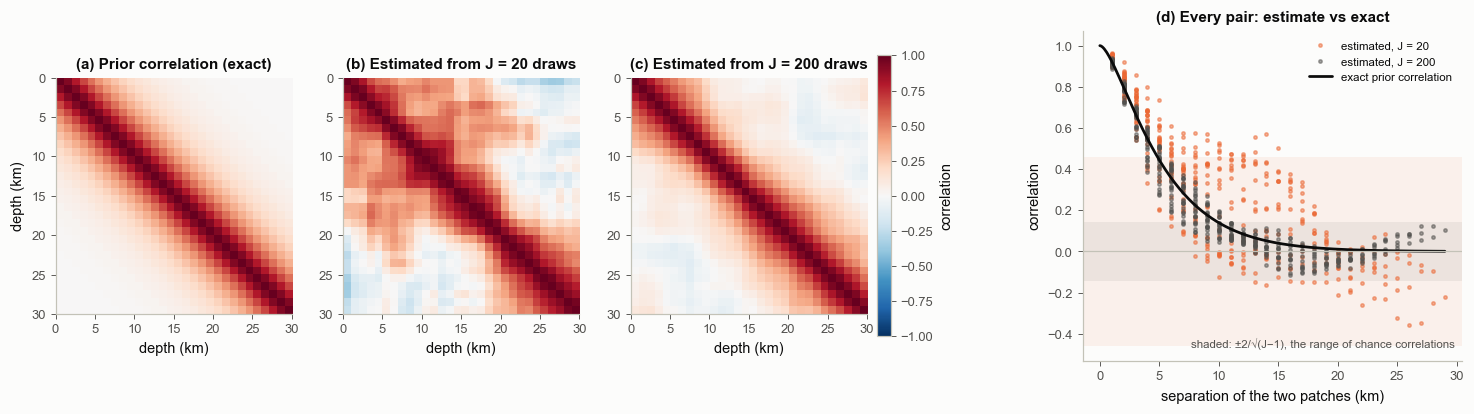

In [3]:
Cor = Cm / np.sqrt(np.outer(np.diag(Cm), np.diag(Cm)))
fig, axs = plt.subplots(1, 4, figsize=(16.5, 3.9), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.35]))
for ax, (J, title) in zip(axs[:3], [(None, "(a) Prior correlation (exact)"), (20, "(b) Estimated from J = 20 draws"),
                                     (200, "(c) Estimated from J = 200 draws")]):
    Cs = Cor if J is None else np.corrcoef(prior_draws(J, 3).T)
    im = ax.imshow(Cs, cmap="RdBu_r", vmin=-1, vmax=1, extent=(0, 30, 30, 0))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("depth (km)")
axs[0].set_ylabel("depth (km)")
fig.colorbar(im, ax=axs[:3], shrink=0.85, pad=0.01, label="correlation")
ax = axs[3]
iu = np.triu_indices(N, 1)
for J, col in [(20, LOC), (200, S.INK2)]:
    R = np.corrcoef(prior_draws(J, 3).T)
    ax.plot(DIST[iu], R[iu], "o", ms=2.2, color=col, alpha=0.5, label=f"estimated, J = {J}")
    ax.axhspan(-2 / np.sqrt(J - 1), 2 / np.sqrt(J - 1), color=col, alpha=0.08, lw=0)
sep = np.linspace(0, 29, 300)
ax.plot(sep, matern_corr(sep), color=S.INK, lw=1.8, label="exact prior correlation")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("separation of the two patches (km)")
ax.set_ylabel("correlation")
ax.set_title("(d) Every pair: estimate vs exact", fontsize=10)
ax.legend(fontsize=7.5, loc="upper right")
ax.text(0.98, 0.04, "shaded: ±2/√(J−1), the range of chance correlations", transform=ax.transAxes, ha="right",
        fontsize=7.5, color=S.INK2)
bk.savefig(fig, "2-26_sampling_error")
plt.show()

**How to read it.** Panel (a) is the prior the members were drawn from: correlation decays over about 10 km. With
20 draws (b) the near-diagonal structure is there, but far from the diagonal the matrix is speckled with
correlations that the prior does not contain. With 200 draws (c) the speckle is much fainter. Panel (d) plots every
pair: beyond about 15 km the exact correlation is nearly zero, and the J = 20 estimates (orange) scatter across the
wide orange band, the J = 200 estimates (grey) across the narrow grey one.

**Worked example.** Two independent quantities, J = 20 draws each, repeated 20,000 times; and the rank of the
J = 20 sample covariance of the 30 slip patches.

In [4]:
rng = np.random.default_rng(0)
J = 20
a_, b_ = rng.standard_normal((2, 20000, J))
r_ = np.array([np.corrcoef(a_[i], b_[i])[0, 1] for i in range(20000)])
print(f"sd of the sample correlation of two INDEPENDENT quantities, J = {J}: {r_.std():.3f}")
print(f"theory 1/sqrt(J-1) = {1 / np.sqrt(J - 1):.3f};  share of |r| > 0.3: {np.mean(np.abs(r_) > 0.3):.3f}")
print(f"rank of the J = {J} sample covariance of the {N} patches: {np.linalg.matrix_rank(np.cov(prior_draws(J, 3).T))}"
      f"  (at most J - 1 = {J - 1})")

sd of the sample correlation of two INDEPENDENT quantities, J = 20: 0.231
theory 1/sqrt(J-1) = 0.229;  share of |r| > 0.3: 0.200
rank of the J = 20 sample covariance of the 30 patches: 19  (at most J - 1 = 19)


**Common misreadings.**
* "More iterations will average the noise out." The iterations reuse the same members; the sampling error of the
  initial ensemble stays in every update.
* "A correlation of 0.3 from 20 members is a finding." It is within the chance range printed above.

## 2. Tapering: multiply the sample covariance by a function that dies off with distance

**In plain words.** If we already believe that patches far apart are nearly uncorrelated, we can enforce that belief:
multiply each entry of the sample covariance by a weight that is 1 for a patch with itself, falls with distance, and
reaches exactly 0 at a chosen cut-off. Nearby pairs keep what the ensemble says; distant pairs lose it.

**Precisely.** The localized covariance is the **Schur (element-wise) product**
$\tilde{\mathbf C} = \boldsymbol\Psi\circ\hat{\mathbf C}$, $\Psi_{ij} = \psi(|z_i-z_j|/c)$, with $\psi$ the
Gaspari-Cohn function (a compactly supported approximation of a Gaussian; Gaspari & Cohn 1999) and $c$ the
**localization length** (the taper is zero beyond $2c$). Tong & Morzfeld (2023, p. 2): "In essence, localization
enforces on the sample covariance from an ensemble the assumption that the covariance between two locations will be
small for sufficiently large separations." Because $\boldsymbol\Psi$ is itself a correlation matrix, the Schur
product theorem keeps $\tilde{\mathbf C}$ positive semidefinite, and its rank can exceed $J-1$: "Localization,
however, also boosts the rank of the ensemble covariance and is, more generally, a technique for reducing sampling
error" (p. 2). The price is bias: if $c$ is too short, real correlations are cut. Gilpin et al. (2025, p. 2):
localization removes spurious correlations "at the cost of introducing a small bias."

In [5]:
print(inspect.getsource(gaspari_cohn))

def gaspari_cohn(r):
    """Gaspari & Cohn (1999) fifth-order piecewise rational taper; r = distance / c. Equal to 1 at r = 0 and exactly 0
    for r >= 2, so c is half the distance at which correlations are cut off."""
    r = np.abs(np.asarray(r, float))
    out = np.zeros_like(r)
    a, b = r <= 1, (r > 1) & (r < 2)
    x = r[a]
    out[a] = -0.25 * x ** 5 + 0.5 * x ** 4 + 0.625 * x ** 3 - 5 / 3 * x ** 2 + 1
    x = r[b]
    out[b] = x ** 5 / 12 - 0.5 * x ** 4 + 0.625 * x ** 3 + 5 / 3 * x ** 2 - 5 * x + 4 - 2 / (3 * x)
    return out



saved figures/2-26_taper.png


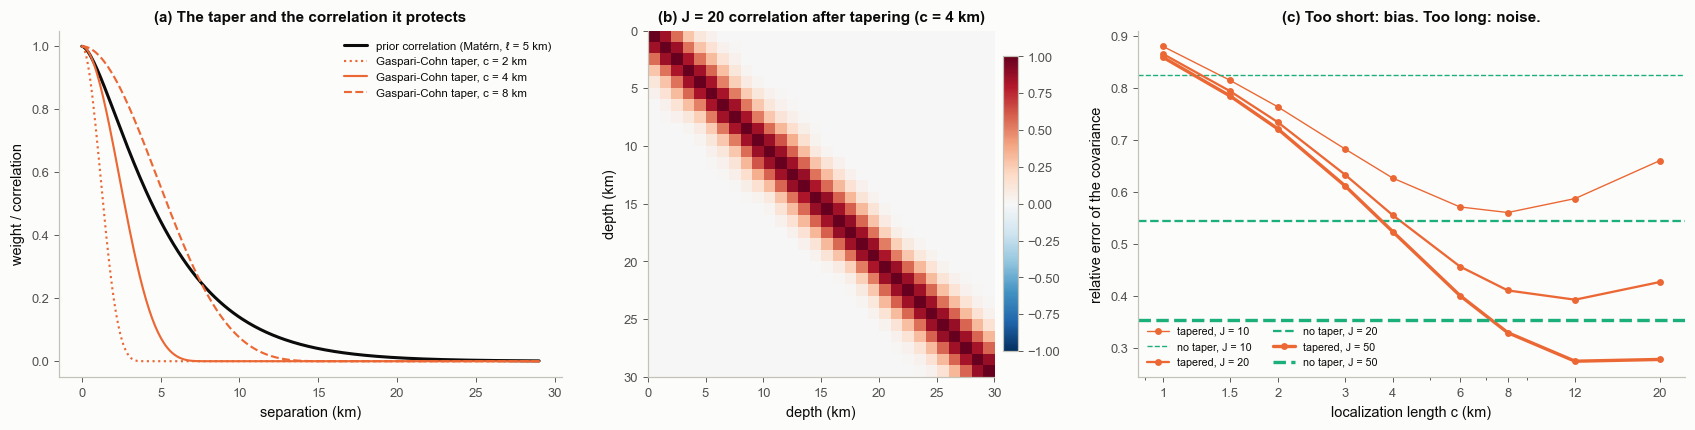

In [6]:
cs = np.array([1, 1.5, 2, 3, 4, 6, 8, 12, 20])
Js_cov = [10, 20, 50]
cov_err = {J: np.zeros((50, cs.size + 1)) for J in Js_cov}
for J in Js_cov:
    for s_ in range(50):
        Ch = np.cov(prior_draws(J, 1000 + s_).T)
        cov_err[J][s_, -1] = np.linalg.norm(Ch - Cm) / np.linalg.norm(Cm)
        for k, c in enumerate(cs):
            cov_err[J][s_, k] = np.linalg.norm(gaspari_cohn(DIST / c) * Ch - Cm) / np.linalg.norm(Cm)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.0), gridspec_kw=dict(width_ratios=[1.15, 1, 1.25]))
ax = axs[0]
ax.plot(sep, matern_corr(sep), color=S.INK, lw=2, label="prior correlation (Matérn, ℓ = 5 km)")
for c, ls in [(2, ":"), (4, "-"), (8, "--")]:
    ax.plot(sep, gaspari_cohn(sep / c), color=LOC, lw=1.4, ls=ls, label=f"Gaspari-Cohn taper, c = {c} km")
ax.set_xlabel("separation (km)"); ax.set_ylabel("weight / correlation")
ax.set_title("(a) The taper and the correlation it protects", fontsize=10)
ax.legend(fontsize=7.5)
ax = axs[1]
Ch = np.cov(prior_draws(20, 3).T)
Ct = gaspari_cohn(DIST / 4) * Ch
im = ax.imshow(Ct / np.sqrt(np.outer(np.diag(Ct), np.diag(Ct))), cmap="RdBu_r", vmin=-1, vmax=1, extent=(0, 30, 30, 0))
ax.set_title("(b) J = 20 correlation after tapering (c = 4 km)", fontsize=10)
ax.set_xlabel("depth (km)"); ax.set_ylabel("depth (km)")
fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
ax = axs[2]
for J, lw in zip(Js_cov, [0.9, 1.5, 2.2]):
    e = cov_err[J].mean(0)
    ax.semilogx(cs, e[:-1], "o-", color=LOC, lw=lw, ms=3.5, label=f"tapered, J = {J}")
    ax.axhline(e[-1], color=STO, lw=lw, ls="--", label=f"no taper, J = {J}")
ax.set_xticks(cs); ax.set_xticklabels([f"{c:g}" for c in cs])
ax.set_xlabel("localization length c (km)"); ax.set_ylabel("relative error of the covariance")
ax.set_title("(c) Too short: bias. Too long: noise.", fontsize=10)
ax.legend(fontsize=7, ncol=2, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-26_taper")
plt.show()

**How to read it.** (a) The taper is a weight curve laid over the prior correlation: with c = 2 km it cuts
correlations the prior really has; with c = 8 km it keeps almost all of them. (b) The same 20 draws as in section 1
panel (b), tapered: the distant speckle is gone and the band around the diagonal survives. (c) The error of the
covariance estimate against the exact prior covariance, averaged over 50 ensembles: every tapered curve has a minimum
at an intermediate c, and below the untapered (dashed) level for the same J over a range of c.

**Worked example.** Rank and error of the J = 20 covariance before and after tapering.

In [7]:
for J in Js_cov:
    e = cov_err[J].mean(0)
    k = int(np.argmin(e[:-1]))
    print(f"J = {J:2d}: relative error untapered {e[-1]:.2f}; best tapered {e[k]:.2f} at c = {cs[k]:g} km")
Ch = np.cov(prior_draws(20, 3).T)
print(f"rank of the J = 20 sample covariance: {np.linalg.matrix_rank(Ch)};  after tapering with c = 4 km: "
      f"{np.linalg.matrix_rank(gaspari_cohn(DIST / 4) * Ch)} (of {N})")
print(f"smallest eigenvalue after tapering: {np.linalg.eigvalsh(gaspari_cohn(DIST / 4) * Ch).min():.2e}  (>= 0: positive semidefinite)")

J = 10: relative error untapered 0.82; best tapered 0.56 at c = 8 km
J = 20: relative error untapered 0.54; best tapered 0.39 at c = 12 km
J = 50: relative error untapered 0.35; best tapered 0.28 at c = 12 km
rank of the J = 20 sample covariance: 19;  after tapering with c = 4 km: 30 (of 30)
smallest eigenvalue after tapering: 1.49e-02  (>= 0: positive semidefinite)


**Common misreadings.**
* "Localization is a smoothing prior." It does not change the prior; it changes how well a small ensemble *estimates*
  the covariances the update uses. With J → ∞ a sensible taper should matter less and less.
* "The best c equals the prior correlation length." Panel (c) puts the best c where bias and noise balance, which
  depends on J.

## 3. Where the taper enters the update

**In plain words.** The Kalman update needs two covariances: between each parameter and each predicted datum (which
parameter moves when a datum misfits) and among the predicted data. A GPS station on the surface sees slip at many
depths, so a datum has no single depth to measure distance from. Tong & Morzfeld's way out is to taper the
*parameter* covariance, where distance is clear, and carry it to the data through the forward model's linearisation.

**Precisely.** For member $j$ and tempering step $\Delta\theta$ ($\alpha = 1/\Delta\theta$, as in the EnKI of 2.24):

$$\mathbf m_j \leftarrow \mathbf m_j + \tilde{\mathbf C}_{mp}\big(\tilde{\mathbf C}_{pp} + \alpha\mathbf C_d\big)^{-1}
\big(\mathbf d + \sqrt{\alpha}\,\boldsymbol\varepsilon_j - \mathcal G(\mathbf m_j)\big),\qquad
\boldsymbol\varepsilon_j\sim\mathcal N(\mathbf 0, \mathbf C_d),$$

with, without localization, $\hat{\mathbf C}_{mp}$ and $\hat{\mathbf C}_{pp}$ straight from the ensemble, and with
**linearised localization** (Tong & Morzfeld 2023, eqs. 3.2-3.3)
$\tilde{\mathbf C}_{mm} = \boldsymbol\Psi\circ\hat{\mathbf C}_{mm}$,
$\tilde{\mathbf C}_{mp} = \tilde{\mathbf C}_{mm}\mathbf H^{\mathsf T}$,
$\tilde{\mathbf C}_{pp} = \mathbf H\tilde{\mathbf C}_{mm}\mathbf H^{\mathsf T}$, where $\mathbf H$ is $\mathbf G$ for
a linear problem and an approximate Jacobian otherwise. Tong & Morzfeld (p. 6) are frank about the cost: "Admittedly,
finding the Jacobian is computationally difficult and defeats the purpose of using LEKI as a derivative free
algorithm", and add that their analysis "does not require the exact Jacobian, but rather an approximation". For data
that do sit at a location (a borehole, a tide gauge above a patch) they also give a **centralized** scheme that tapers
$\hat{\mathbf C}_{mp}$ directly by parameter-datum distance (eq. 3.4, p. 7).

**Why the stochastic form and not the ETKF.** The square-root update of 2.24 works with a $J\times J$ transform and never
forms $\hat{\mathbf C}_{mm}$, so there is nothing to multiply by a taper. Gilpin et al. (2025, p. 3) use the
perturbed-observation EnKF "so that we can apply the various localization techniques directly to the forecast
covariance matrix". For transform filters, Gjini et al. (2025, p. 26): "Localization in transform filters (ETKI) is
typically done by considering variables, or sets of variables, independently" (a **local analysis**, as in the
LETKF; not built here). The perturbations $\boldsymbol\varepsilon_j$ are centred over the members so they add no
noise to the mean.

**The subspace property, and how localization breaks it.** Without a taper, $\hat{\mathbf C}_{mp} =
\mathbf A\mathbf B^{\mathsf T}/(J-1)$, so every update adds a combination of the current anomalies: Tong & Morzfeld
(p. 2), "all ensemble members [...] are confined to the linear subspace $S_0$ spanned by the initial ensemble". With a
taper, $\tilde{\mathbf C}_{mm}$ has full rank and the update can point anywhere.

In [8]:
print(inspect.getsource(enki_local))

def enki_local(fwd, y, sigma, X0, rng, taper=None, jac=None, update="stochastic", max_dtheta=1.0, inflation=1.0,
               maxit=40):
    """Tempered EnKI with optional localization.

    fwd(X): (J, d) -> (J, M) forward runs.  taper: (d, d) Gaspari-Cohn matrix, or None for no localization.
    jac: a function m -> H (M, d) evaluated at the ensemble mean each iteration, or a fixed matrix H.
    update: "etkf"  = the square-root update of 2.24 (bayeskit.samplers.etkf_update);
            "stochastic" = perturbed observations, the form in which a covariance can be tapered.
    Step size: Iglesias & Yang, dtheta = min(max(WRMS^-2, sqrt(M / (2 Var Phi))), max_dtheta, 1 - theta), as in 2.24.
    """
    X = np.array(X0, float)
    J, M = X.shape[0], y.size
    sig = np.broadcast_to(np.asarray(sigma, float), (M,))
    theta, hist, n_fwd, n_jac = 0.0, [], 0, 0
    while True:
        Y = fwd(X)
        n_fwd += J
        chi = np.sum(((y - Y) / sig) ** 2, axis=1)
        wrms = np.sqrt(c

## 4. The linear slip problem: J = 20 and J = 50 members for 30 unknowns

Three updates, two seeds each, graded against the exact posterior: the ETKF EnKI of 2.24 (`SM.enki` algebra), the
stochastic update without localization, and the stochastic update with linearised localization at c = 4 km (about the
prior correlation length; section 5 scans c). All start from the same prior draws for a given seed.

In [9]:
METHODS = [("ETKF (EnKI of 2.24)", dict(update="etkf"), EN),
           ("stochastic, no localization", dict(update="stochastic"), STO),
           ("localized, c = 4 km", dict(update="stochastic", taper=gaspari_cohn(DIST / 4.0), jac=G), LOC)]
runs = {}
for J in (20, 50):
    for name, kw, _ in METHODS:
        for seed in (1, 2):
            runs[(J, name, seed)] = enki_local(fwd_lin, d, sigma, prior_draws(J, seed), np.random.default_rng(100 + seed), **kw)
print(f"{'J':>3s}  {'method':30s} {'seed':>4s} {'iters':>5s} {'forward runs':>12s} {'mean err (sd)':>13s} "
      f"{'sd ratio':>8s} {'outside span':>12s}")
for (J, name, seed), r in runs.items():
    e, sr = grade(r["X"], m_ex, sd_ex)
    print(f"{J:3d}  {name:30s} {seed:4d} {len(r['hist']) - 1:5d} {r['n_fwd']:12d} {e:13.2f} {sr:8.2f} "
          f"{outside_span(r['X0'], r['X']):12.1e}")
for J in (20, 50):
    for name, _, _ in METHODS:
        print(f"J = {J}, {name:30s}: seed-to-seed gap {seed_gap(runs[(J, name, 1)]['X'], runs[(J, name, 2)]['X']):.2f} own sd")
print("(for J = 50 > 30 unknowns the initial anomalies already span all 30 directions, so 'outside span' is 0 for every method)")

  J  method                         seed iters forward runs mean err (sd) sd ratio outside span
 20  ETKF (EnKI of 2.24)               1     6          140          0.40     0.81      6.5e-16
 20  ETKF (EnKI of 2.24)               2     6          140          0.62     0.86      9.6e-16
 20  stochastic, no localization       1     6          140          0.46     0.58      8.1e-16
 20  stochastic, no localization       2     6          140          0.54     0.53      1.5e-15
 20  localized, c = 4 km               1     7          160          0.47     0.94      6.0e-02
 20  localized, c = 4 km               2     7          160          0.42     0.95      8.2e-02
 50  ETKF (EnKI of 2.24)               1     6          350          0.33     0.97      3.1e-15
 50  ETKF (EnKI of 2.24)               2     6          350          0.37     1.01      1.1e-15
 50  stochastic, no localization       1     6          350          0.43     0.86      2.6e-15
 50  stochastic, no localization       2

saved figures/2-26_linear_profiles.png


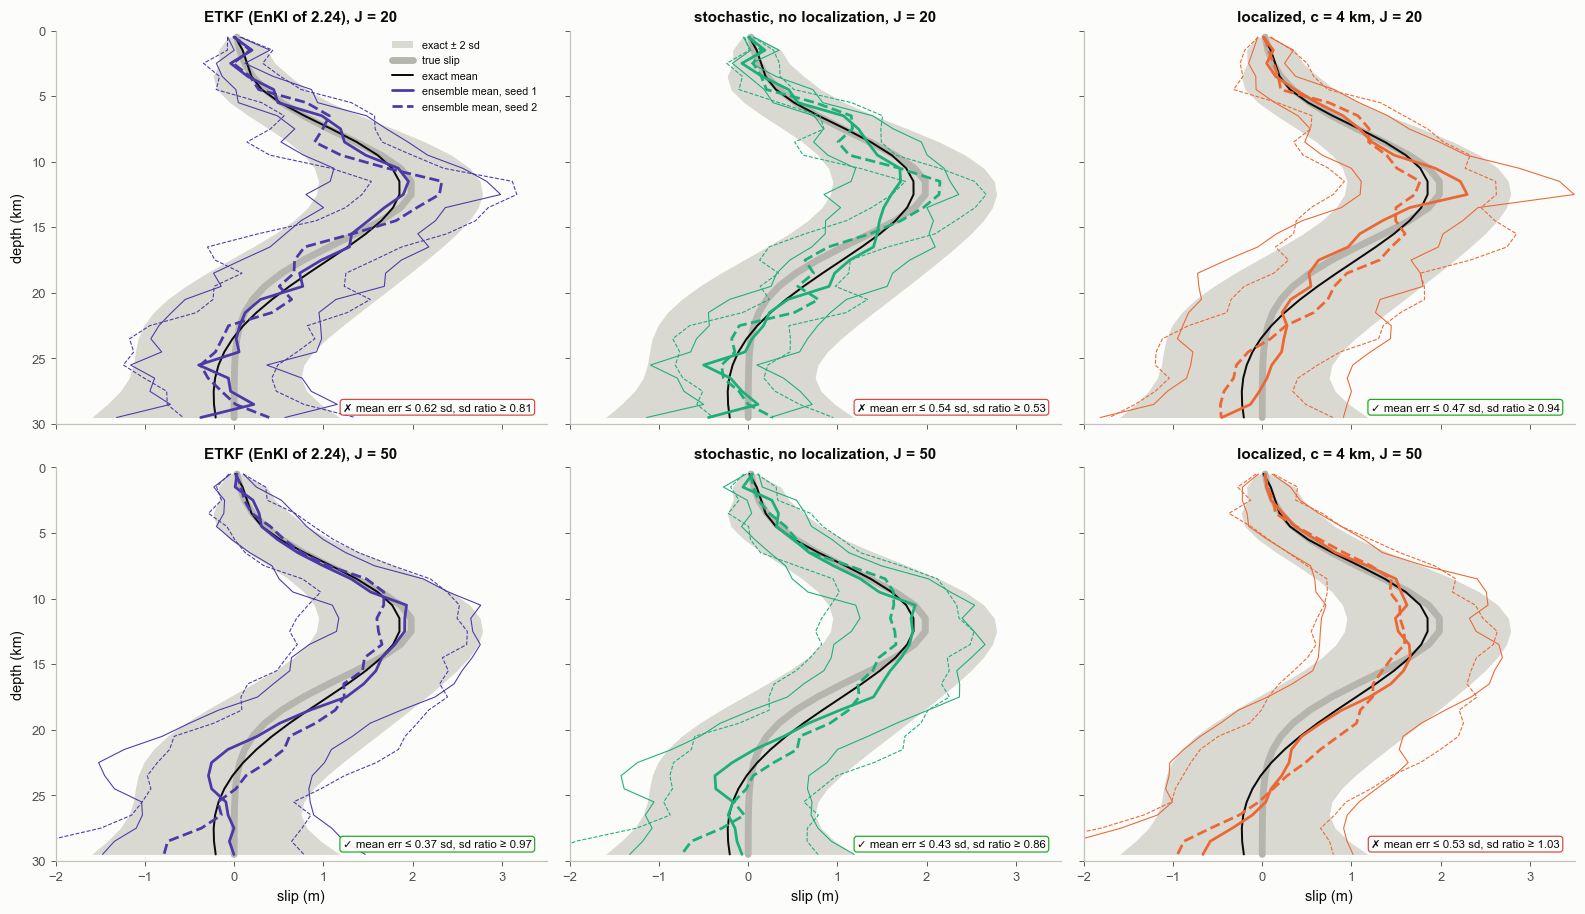

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(14.5, 8.4), sharey=True, sharex=True)
for i, J in enumerate((20, 50)):
    for k, (name, _, col) in enumerate(METHODS):
        ax = axs[i, k]
        ax.fill_betweenx(zc, m_ex - 2 * sd_ex, m_ex + 2 * sd_ex, color=EXACT_FILL, lw=0, label="exact ± 2 sd")
        ax.plot(s_true, zc, **TRUE_KW, label="true slip")
        ax.plot(m_ex, zc, color=S.INK, lw=1.3, label="exact mean")
        errs = []
        for seed, ls in ((1, "-"), (2, "--")):
            X = runs[(J, name, seed)]["X"]
            m, s = X.mean(0), X.std(0, ddof=1)
            ax.plot(m, zc, color=col, lw=1.8, ls=ls, label=f"ensemble mean, seed {seed}")
            ax.plot(m - 2 * s, zc, color=col, lw=0.7, ls=ls)
            ax.plot(m + 2 * s, zc, color=col, lw=0.7, ls=ls)
            errs.append(grade(X, m_ex, sd_ex))
        e = max(errs[0][0], errs[1][0])
        sr = min(errs[0][1], errs[1][1])
        S.badge(ax, f"mean err ≤ {e:.2f} sd, sd ratio ≥ {sr:.2f}", ok=(e < 0.5 and sr > 0.8), loc="lower right", fs=7.5)
        ax.set_title(f"{name}, J = {J}", fontsize=10)
        ax.set_ylim(30, 0); ax.set_xlim(-2.0, 3.5)
    axs[i, 0].set_ylabel("depth (km)")
for ax in axs[1]:
    ax.set_xlabel("slip (m)")
axs[0, 0].legend(fontsize=7, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-26_linear_profiles")
plt.show()

**How to read it.** Grey band and black line: the exact posterior. Coloured lines: ensemble mean and ±2 sd for two
seeds (solid, dashed). Badge ✓ when both seeds have mean error below 0.5 exact sd and spread ratio above 0.8 (both
printed in the table above).
* **J = 20 < 30 unknowns.** The table's "outside span" column is zero to round-off for the two unlocalized updates
  and clearly non-zero for the localized one: the subspace property, measured, and broken.
* Compare the spread ratio across the J = 20 row: the unlocalized ensembles end up narrower than the exact posterior
  (the stochastic one much narrower); the localized one is much closer to the exact width.
* The mean error at J = 20 is similar for the three updates in this two-seed comparison; section 5 repeats it with 20
  seeds, which is the fairer test.
* **J = 50 > 30 unknowns.** Read the J = 50 rows of the table: with enough members the unlocalized updates are
  already close to exact, and localization has little left to fix.

## 5. Choosing the localization length: the bias-variance trade-off, with 20 seeds

The comparison above is two seeds. Here each setting runs 20 seeds, for J = 10, 20, 50 and c from 1 to 20 km. The
dotted line is a benchmark: the error of $J$ **independent** draws from the exact posterior (an "ideal sampler").
It is a reference point for this statistic, not a bound that no method can beat: an ensemble whose members are
deliberately arranged (for example in mirror-image pairs, or with moments matched exactly) can estimate a mean with
less error than independent draws.

saved figures/2-26_radius_tradeoff.png


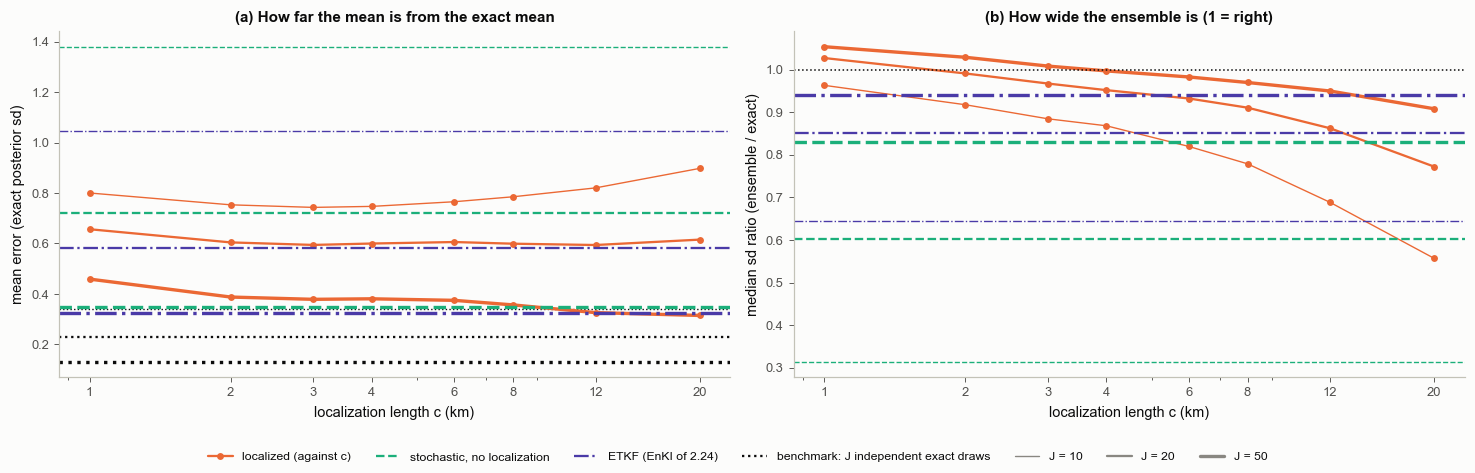

  J    setting  mean err  sd ratio   (averages over 20 seeds)
 10      ideal      0.34      0.97
 10       etkf      1.05      0.64
 10        sto      1.38      0.31
 10      c = 1      0.80      0.96
 10      c = 2      0.75      0.92
 10      c = 3      0.74      0.88
 10      c = 4      0.75      0.87
 10      c = 6      0.77      0.82
 10      c = 8      0.78      0.78
 10     c = 12      0.82      0.69
 10     c = 20      0.90      0.56
 20      ideal      0.23      1.02
 20       etkf      0.58      0.85
 20        sto      0.72      0.60
 20      c = 1      0.66      1.03
 20      c = 2      0.60      0.99
 20      c = 3      0.59      0.97
 20      c = 4      0.60      0.95
 20      c = 6      0.61      0.93
 20      c = 8      0.60      0.91
 20     c = 12      0.59      0.86
 20     c = 20      0.62      0.77
 50      ideal      0.13      0.99
 50       etkf      0.32      0.94
 50        sto      0.35      0.83
 50      c = 1      0.46      1.05
 50      c = 2      0.39    

In [11]:
cs_run = np.array([1, 2, 3, 4, 6, 8, 12, 20])
Js = [10, 20, 50]
NSEED = 20
sweep = {}
for J in Js:
    for s_ in range(NSEED):
        X0 = prior_draws(J, 500 + s_)
        rng_ = lambda: np.random.default_rng(900 + s_)
        sweep[(J, "etkf", s_)] = enki_local(fwd_lin, d, sigma, X0, rng_(), update="etkf")["X"]
        sweep[(J, "sto", s_)] = enki_local(fwd_lin, d, sigma, X0, rng_())["X"]
        for c in cs_run:
            sweep[(J, c, s_)] = enki_local(fwd_lin, d, sigma, X0, rng_(), taper=gaspari_cohn(DIST / c), jac=G)["X"]
        ideal = m_ex + (np.linalg.cholesky(C_ex + 1e-12 * np.eye(N)) @ np.random.default_rng(700 + s_).standard_normal((N, J))).T
        sweep[(J, "ideal", s_)] = ideal


def avg(J, key):
    g_ = np.array([grade(sweep[(J, key, s_)], m_ex, sd_ex) for s_ in range(NSEED)])
    return g_.mean(0)


fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.3))
for J, lw in zip(Js, [0.9, 1.5, 2.2]):
    curve = np.array([avg(J, c) for c in cs_run])
    for k, ax in enumerate(axs):
        ax.semilogx(cs_run, curve[:, k], "o-", color=LOC, lw=lw, ms=3.5, label=f"localized, J = {J}")
        ax.axhline(avg(J, "sto")[k], color=STO, lw=lw, ls="--", label=f"stochastic, no localization, J = {J}")
        ax.axhline(avg(J, "etkf")[k], color=EN, lw=lw, ls="-.", label=f"ETKF, J = {J}")
        if k == 0:
            ax.axhline(avg(J, "ideal")[0], color=S.INK, lw=lw, ls=":", label=f"benchmark: J independent exact draws, J = {J}")
axs[1].axhline(1.0, color=S.INK, lw=1, ls=":")
for ax, lab in zip(axs, ["mean error (exact posterior sd)", "median sd ratio (ensemble / exact)"]):
    ax.set_xticks(cs_run); ax.set_xticklabels([f"{c:g}" for c in cs_run])
    ax.set_xlabel("localization length c (km)"); ax.set_ylabel(lab)
axs[0].set_title("(a) How far the mean is from the exact mean", fontsize=10)
axs[1].set_title("(b) How wide the ensemble is (1 = right)", fontsize=10)
from matplotlib.lines import Line2D
hl = [Line2D([], [], color=LOC, marker="o", ms=3.5, lw=1.5, label="localized (against c)"),
      Line2D([], [], color=STO, ls="--", lw=1.5, label="stochastic, no localization"),
      Line2D([], [], color=EN, ls="-.", lw=1.5, label="ETKF (EnKI of 2.24)"),
      Line2D([], [], color=S.INK, ls=":", lw=1.5, label="benchmark: J independent exact draws")] + \
     [Line2D([], [], color=S.MUTED, lw=lw, label=f"J = {J}") for J, lw in zip(Js, [0.9, 1.5, 2.2])]
fig.legend(handles=hl, loc="lower center", ncol=7, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
bk.savefig(fig, "2-26_radius_tradeoff")
plt.show()
print(f"{'J':>3s} {'setting':>10s} {'mean err':>9s} {'sd ratio':>9s}   (averages over {NSEED} seeds)")
for J in Js:
    for key in ["ideal", "etkf", "sto"] + list(cs_run):
        e, sr = avg(J, key)
        print(f"{J:3d} {('c = %g' % key) if not isinstance(key, str) else key:>10s} {e:9.2f} {sr:9.2f}")

**How to read it.** Orange curves: localized EnKI against c; dashed aqua: stochastic without localization; dash-dot
violet: the ETKF; dotted black: the independent-draws benchmark.
* **Spread (b).** Without localization the ensemble is too narrow, and more so for smaller J (the table). Localization
  brings the spread ratio close to 1 at short c and lets it drift down again as c grows toward "no taper".
* **Mean (a).** Read the table rows for each J. At J = 10 (a third of the unknowns) localization lowers the mean
  error well below both unlocalized updates, for every c. At J = 20 it matches the ETKF's mean error and beats the
  unlocalized stochastic update, while fixing the spread. At J = 50 the unlocalized and ETKF means are already about as
  good, and the shortest c adds bias. In these runs every ensemble method stays above the independent-draws line:
  the sampling error in the gain is not fully removed.
* In this linear problem the mean error at J = 20 is flat over a wide range of c, so the exact choice of c matters
  less than whether to localize at all.
* The image to keep: localization is worth the most exactly where you need it, with few members per unknown.

## 6. Inflation: a crude fix for the spread, not for the mean

**In plain words.** Small ensembles end up too narrow. **Multiplicative inflation** simply widens the ensemble around
its mean by a factor $r$ before every update. It is cheap and common, but it adds no new directions: a member set that
cannot reach part of the answer still cannot.

**Precisely.** $\mathbf m_j \leftarrow \bar{\mathbf m} + r(\mathbf m_j-\bar{\mathbf m})$ before each tempering step.
Because the step is repeated at every iteration, the widening compounds, roughly $r^{n}$ after $n$ steps.

saved figures/2-26_inflation.png


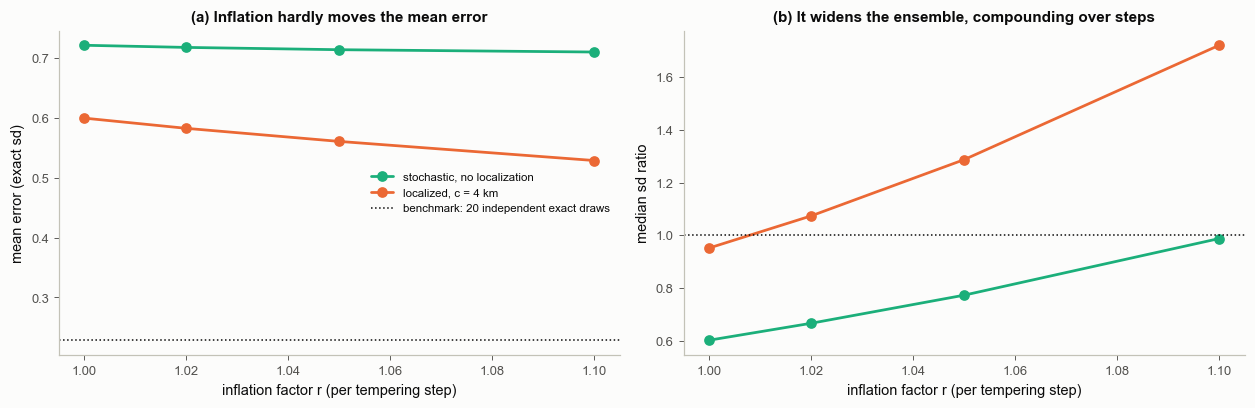

r = 1.00  sto : mean err 0.72, sd ratio 0.60, mean number of steps 6.3, r^steps = 1.00
r = 1.00  loc : mean err 0.60, sd ratio 0.95, mean number of steps 6.8, r^steps = 1.00
r = 1.02  sto : mean err 0.72, sd ratio 0.67, mean number of steps 6.3, r^steps = 1.13
r = 1.02  loc : mean err 0.58, sd ratio 1.07, mean number of steps 6.9, r^steps = 1.15
r = 1.05  sto : mean err 0.71, sd ratio 0.77, mean number of steps 6.2, r^steps = 1.35
r = 1.05  loc : mean err 0.56, sd ratio 1.29, mean number of steps 6.9, r^steps = 1.40
r = 1.10  sto : mean err 0.71, sd ratio 0.99, mean number of steps 6.2, r^steps = 1.81
r = 1.10  loc : mean err 0.53, sd ratio 1.72, mean number of steps 6.9, r^steps = 1.93


In [12]:
rs = [1.0, 1.02, 1.05, 1.1]
infl = {}
for r_inf in rs:
    for key, kw in [("sto", {}), ("loc", dict(taper=gaspari_cohn(DIST / 4.0), jac=G))]:
        out = []
        for s_ in range(NSEED):
            res = enki_local(fwd_lin, d, sigma, prior_draws(20, 500 + s_), np.random.default_rng(900 + s_), inflation=r_inf, **kw)
            out.append(grade(res["X"], m_ex, sd_ex) + (len(res["hist"]) - 1,))
        infl[(r_inf, key)] = np.array(out).mean(0)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
for key, col, lab in [("sto", STO, "stochastic, no localization"), ("loc", LOC, "localized, c = 4 km")]:
    v = np.array([infl[(r_inf, key)] for r_inf in rs])
    axs[0].plot(rs, v[:, 0], "o-", color=col, lw=1.8, label=lab)
    axs[1].plot(rs, v[:, 1], "o-", color=col, lw=1.8, label=lab)
axs[0].axhline(avg(20, "ideal")[0], color=S.INK, ls=":", lw=1, label="benchmark: 20 independent exact draws")
axs[1].axhline(1.0, color=S.INK, ls=":", lw=1)
axs[0].set_ylabel("mean error (exact sd)"); axs[1].set_ylabel("median sd ratio")
for ax in axs:
    ax.set_xlabel("inflation factor r (per tempering step)")
axs[0].set_title("(a) Inflation hardly moves the mean error", fontsize=10)
axs[1].set_title("(b) It widens the ensemble, compounding over steps", fontsize=10)
axs[0].legend(fontsize=7.5)
fig.tight_layout()
bk.savefig(fig, "2-26_inflation")
plt.show()
for (r_inf, key), v in infl.items():
    print(f"r = {r_inf:4.2f}  {key:4s}: mean err {v[0]:.2f}, sd ratio {v[1]:.2f}, mean number of steps {v[2]:.1f}, "
          f"r^steps = {r_inf ** v[2]:.2f}")

**How to read it.** J = 20, 20 seeds. Panel (b): inflation pushes the spread up, by an amount that depends on how
many tempering steps the run takes (printed as $r^{\text{steps}}$), so a factor tuned for one data set or step cap
does not transfer to another. Panel (a): the mean error changes far less than the spread (printed), and for the
unlocalized update it stays near its uninflated value. Inflation and localization treat different symptoms;
operational data assimilation usually uses both.

## 7. A nonlinear problem: frictional strength with depth from postseismic GPS

Now the afterslip forward model also used in topic 3 (`bayeskit.afterslip`): a vertical strike-slip fault with 40 patches, coseismic
slip from 0 to 12 km, and stress-driven afterslip on the 31 patches whose stress rose. The unknown is the depth
profile $\log a\sigma(z)$ on those 31 patches (the 9 pinned patches do not slip, so the data say nothing about them),
with the module's Matérn prior (ℓ = 8 km, ν = 1.5, sd 0.5 around $\log 0.8$ MPa). Data: surface displacement at 30
stations after 1 day, 1 week, 1 month, 3 months and 1 year, σ = 2 mm. Afterslip grows roughly logarithmically in
time with an amplitude set by $a\sigma$, and its onset depends exponentially on $\Delta\tau/a\sigma$: a nonlinear
forward model.

**A fast solver for many runs.** The module's diffrax solver is accurate but too slow for the thousands of runs the
reference below needs (its time per run is printed below). The cell below integrates the same equations with a fixed sequence of
log-spaced implicit (backward-Euler) steps, vectorised over all members at once, and recovers slip from the
stress-slip relation $\boldsymbol\tau = \Delta\boldsymbol\tau + \mathbf K\mathbf s$. It is checked against the
diffrax black box on prior draws. Synthetic data and every inversion below use this solver, so the comparison
between methods is exact; the check says how close it is to the black box.

In [13]:
setup = AS.fault_setup()
free = setup["free"]
zf = setup["zc"][free]
nf = int(free.sum())
T_D = np.array([1 / 365.25, 7 / 365.25, 30 / 365.25, 0.25, 1.0])
EPOCHS = ["1 day", "1 week", "1 month", "3 months", "1 year"]
Kf = jnp.asarray(setup["K"][np.ix_(free, free)])
dtf = jnp.asarray(setup["dtau"][free])
Gs = jnp.asarray(setup["G"][:, free])
NSTEP = 300
t_grid = np.unique(np.r_[0.0, np.geomspace(1e-7, 1.0, NSTEP), T_D])
h_steps = jnp.asarray(np.diff(t_grid))
i_obs = np.where(np.isin(t_grid[1:], T_D))[0]


def afterslip_be(log_as, v0=0.03):
    """Afterslip on the free patches at T_D, (5, 31) metres: backward Euler in log-spaced time, 6 Newton iterations
    per step started from the exact solution of the patch-by-patch (diagonal) implicit equation."""
    a = jnp.exp(log_as)
    I = jnp.eye(a.shape[0])
    dK = jnp.abs(jnp.diag(Kf))
    vel = lambda tau: 2 * v0 * jnp.sinh(tau / a)

    def step(tau, h):
        x0, c_ = tau / a, h * dK * 2 * v0 / a
        tn = a * jnp.sign(x0) * jnp.minimum(jnp.abs(x0), jnp.arcsinh(jnp.abs(x0) / c_))

        def newton(tn, _):
            F = tn - tau - h * (Kf @ vel(tn))
            Jm = I - h * Kf * (2 * v0 * jnp.cosh(tn / a) / a)[None, :]
            return tn - jnp.clip(jnp.linalg.solve(Jm, F), -2 * a, 2 * a), None
        tn, _ = jax.lax.scan(newton, tn, None, length=6)
        return tn, tn
    _, taus = jax.lax.scan(step, dtf, h_steps)
    return jnp.linalg.solve(Kf, (taus[i_obs] - dtf).T).T


def surface_mm(log_as):
    return (afterslip_be(log_as) @ Gs.T).ravel() * 1000.0     # (5 epochs x 30 stations), epoch-major, mm


fwd_f = jax.jit(jax.vmap(surface_mm))
jac_f = jax.jit(jax.jacfwd(surface_mm))
fwd_fault = lambda X: np.asarray(fwd_f(jnp.asarray(X)))

Cf = AS.matern_cov(setup["zc"], 8.0, 1.5, 0.5)[np.ix_(free, free)] + 1e-10 * np.eye(nf)
Lf = np.linalg.cholesky(Cf)
mu_f = np.log(0.8)
DIST_F = np.abs(zf[:, None] - zf[None, :])
fault_prior = lambda J, seed: mu_f + (Lf @ np.random.default_rng(seed).standard_normal((nf, J))).T
GAP = int(np.argmax(np.diff(zf))) + 1                                 # pinned patches between zf[GAP-1] and zf[GAP]
zf_plot = np.insert(zf, GAP, np.nan)                                 # plot with a break: the pinned patches are not unknowns
gp = lambda v: np.insert(np.asarray(v, float), GAP, np.nan)

# check against the diffrax black box on 10 prior draws
la_full = AS.sample_log_asig(np.random.default_rng(5), 11, setup["zc"])
bb = jax.jit(lambda l: AS.fault_surface(l, setup, 0.03, T_D))
bb(jnp.asarray(la_full[10])).block_until_ready()                     # compile once
t0 = time.time()
ref_bb = np.array([np.asarray(bb(jnp.asarray(l))) * 1000 for l in la_full[:10]])
t_bb = (time.time() - t0) / 10
mine = fwd_fault(la_full[:10, free]).reshape(10, 5, -1)
X600 = AS.sample_log_asig(np.random.default_rng(6), 600, setup["zc"])[:, free]
fwd_fault(X600)                                                      # compile for this batch size
t0 = time.time()
fwd_fault(X600)
t_me = (time.time() - t0) / 600
print(f"diffrax black box: {t_bb:.3f} s per run;  fast solver: {t_me:.4f} s per run (600 runs at once)")
print(f"max |fast - diffrax| = {np.abs(mine - ref_bb).max():.2f} mm, rms {np.sqrt(np.mean((mine - ref_bb) ** 2)):.2f} mm "
      f"(data noise 2 mm; largest displacement {np.abs(ref_bb).max():.0f} mm)")

la_true = mu_f + Lf @ np.random.default_rng(11).standard_normal(nf)
sig_f = 2.0
y_clean = np.asarray(surface_mm(jnp.asarray(la_true)))
y_f = y_clean + sig_f * np.random.default_rng(12).standard_normal(y_clean.size)
Mf = y_f.size
print(f"{Mf} data, {nf} unknowns; chi^2/N of the true profile against the noisy data: "
      f"{np.mean(((y_f - y_clean) / sig_f) ** 2):.2f}")

diffrax black box: 0.102 s per run;  fast solver: 0.0027 s per run (600 runs at once)
max |fast - diffrax| = 1.64 mm, rms 0.46 mm (data noise 2 mm; largest displacement 520 mm)


150 data, 31 unknowns; chi^2/N of the true profile against the noisy data: 0.89


saved figures/2-26_fault_setup.png


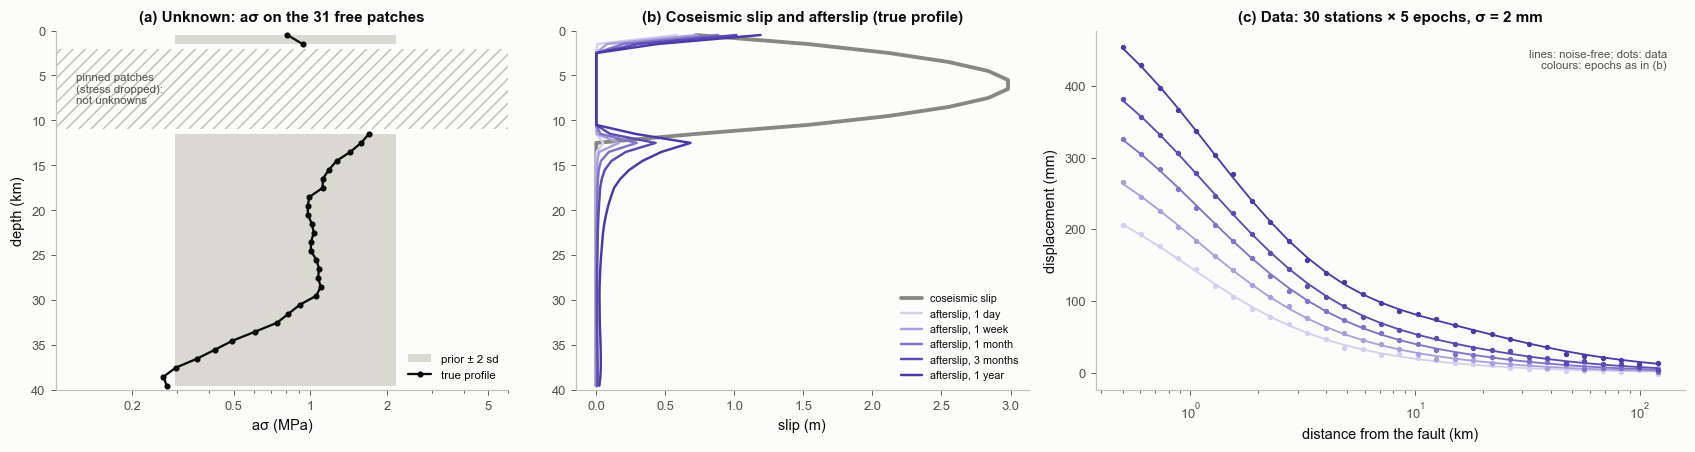

In [14]:
slip_true = np.asarray(afterslip_be(jnp.asarray(la_true)))
fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
ax = axs[0]
sdp = np.sqrt(np.diag(Cf))
ax.fill_betweenx(zf_plot, gp(np.exp(mu_f - 2 * sdp)), gp(np.exp(mu_f + 2 * sdp)), color=EXACT_FILL, lw=0, label="prior ± 2 sd")
ax.axhspan(zf[GAP - 1] + 0.5, zf[GAP] - 0.5, fc="none", ec=S.AXIS, hatch="///", lw=0)
ax.text(0.12, 0.5 * (zf[GAP - 1] + zf[GAP]), "pinned patches\n(stress dropped):\nnot unknowns", fontsize=7.5, va="center", color=S.INK2)
ax.plot(np.exp(gp(la_true)), zf_plot, "o-", color=S.INK, ms=3, lw=1.5, label="true profile")
ax.set_xscale("log"); ax.set_ylim(40, 0); ax.set_xlim(0.1, 6)
ax.set_xticks([0.2, 0.5, 1, 2, 5]); ax.set_xticklabels(["0.2", "0.5", "1", "2", "5"])
ax.set_xlabel("aσ (MPa)"); ax.set_ylabel("depth (km)")
ax.set_title("(a) Unknown: aσ on the 31 free patches", fontsize=10)
ax.legend(fontsize=7.5, loc="lower right")
ax = axs[1]
ax.plot(setup["s_co"], setup["zc"], color=S.MUTED, lw=2.5, label="coseismic slip")
shades = ["#d4cfee", "#ab9fdd", "#8172c7", "#5b4bb2", EN]
slip_all = np.zeros((5, setup["zc"].size))
slip_all[:, free] = slip_true                                       # pinned patches do not slip
for k in range(5):
    ax.plot(slip_all[k], setup["zc"], color=shades[k], lw=1.6, label=f"afterslip, {EPOCHS[k]}")
ax.set_ylim(40, 0); ax.set_xlabel("slip (m)")
ax.set_title("(b) Coseismic slip and afterslip (true profile)", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
ax = axs[2]
xo = setup["x_obs"]
for k in range(5):
    ax.plot(xo, y_clean.reshape(5, -1)[k], color=shades[k], lw=1.2)
    ax.plot(xo, y_f.reshape(5, -1)[k], "o", color=shades[k], ms=2.5)
ax.set_xscale("log"); ax.set_xlabel("distance from the fault (km)"); ax.set_ylabel("displacement (mm)")
ax.set_title("(c) Data: 30 stations × 5 epochs, σ = 2 mm", fontsize=10)
ax.text(0.97, 0.95, "lines: noise-free; dots: data\ncolours: epochs as in (b)", transform=ax.transAxes, ha="right",
        va="top", fontsize=7.5, color=S.INK2)
fig.tight_layout()
bk.savefig(fig, "2-26_fault_setup")
plt.show()

**The reference posterior.** For a nonlinear problem there is no closed form. The reference here is the ETKF EnKI
with J = 600 members (20 times the number of unknowns), with the tempering step capped at $\Delta\theta_{\max}$ = 0.1
(2.24, section 8). That is
the large-ensemble limit of the *same* Gaussian-update method, so it isolates the sampling error that localization
targets; it is not the exact Bayesian posterior (notebook 2.25 measures that gap for EnKI). A second large run, the
stochastic update with another seed, gives the reference's own noise floor.

In [15]:
t0 = time.time()
ref1 = enki_local(fwd_fault, y_f, sig_f, fault_prior(600, 1), np.random.default_rng(1), update="etkf", max_dtheta=0.1)
t_ref = time.time() - t0
ref2 = enki_local(fwd_fault, y_f, sig_f, fault_prior(600, 2), np.random.default_rng(2), max_dtheta=0.1)
m_rf, sd_rf = ref1["X"].mean(0), ref1["X"].std(0, ddof=1)
print(f"reference ETKF, J = 600: {len(ref1['hist']) - 1} steps, {ref1['n_fwd']} forward runs, {t_ref:.0f} s, "
      f"final WRMS {ref1['hist'][-1]['wrms']:.2f}")
e_, sr_ = grade(ref2["X"], m_rf, sd_rf)
print(f"noise floor: second reference (stochastic, J = 600) vs first: mean error {e_:.2f} sd, sd ratio {sr_:.2f}")
print(f"prior sd / reference sd (median over patches): {np.median(np.sqrt(np.diag(Cf)) / sd_rf):.2f};  "
      f"true profile inside reference ± 2 sd on {np.mean(np.abs(la_true - m_rf) < 2 * sd_rf) * 100:.0f} % of patches")

reference ETKF, J = 600: 12 steps, 7800 forward runs, 21 s, final WRMS 0.94
noise floor: second reference (stochastic, J = 600) vs first: mean error 0.11 sd, sd ratio 0.95
prior sd / reference sd (median over patches): 1.51;  true profile inside reference ± 2 sd on 90 % of patches


Now the small ensembles: J = 20 and 50 for 31 unknowns, two seeds each, four updates. The localized runs need
$\mathbf H$, the Jacobian of the 150 predictions with respect to the 31 unknowns. Option 1 computes it at the
ensemble mean every step (JAX forward-mode autodiff through the solver, notebook 2.17: 31 tangent runs per Jacobian).
Option 2 computes it once, at the prior mean, and keeps it, the cheap approximation Tong & Morzfeld allow.

In [16]:
H_prior = np.asarray(jac_f(jnp.asarray(np.full(nf, mu_f))))
H_ref = np.asarray(jac_f(jnp.asarray(m_rf)))
print(f"Jacobian at the prior mean differs from the one at the reference mean by "
      f"{np.linalg.norm(H_prior - H_ref) / np.linalg.norm(H_ref) * 100:.0f} % (Frobenius norm)")
taper_f = gaspari_cohn(DIST_F / 8.0)
jac_np = lambda m: np.asarray(jac_f(jnp.asarray(m)))
F_METHODS = [("ETKF (EnKI of 2.24)", dict(update="etkf"), EN),
             ("stochastic, no localization", dict(update="stochastic"), STO),
             ("localized, H every step", dict(taper=taper_f, jac=jac_np), LOC),
             ("localized, H fixed at prior mean", dict(taper=taper_f, jac=H_prior), LOC2)]
fruns = {}
for J in (20, 50):
    for name, kw, _ in F_METHODS:
        for seed in (3, 4):
            t0 = time.time()
            r = enki_local(fwd_fault, y_f, sig_f, fault_prior(J, seed), np.random.default_rng(seed), max_dtheta=0.1, **kw)
            r["time"] = time.time() - t0
            fruns[(J, name, seed)] = r
print("localization length c = 8 km (the prior correlation length of log aσ)")
print(f"{'J':>3s}  {'method':34s} {'seed':>4s} {'steps':>5s} {'fwd runs':>8s} {'+tangent runs':>13s} {'final WRMS':>10s} "
      f"{'mean err':>8s} {'sd ratio':>8s} {'outside span':>12s}")
for (J, name, seed), r in fruns.items():
    e, sr = grade(r["X"], m_rf, sd_rf)
    print(f"{J:3d}  {name:34s} {seed:4d} {len(r['hist']) - 1:5d} {r['n_fwd']:8d} {r['n_jac'] * nf + (nf if 'fixed' in name else 0):13d} "
          f"{r['hist'][-1]['wrms']:10.2f} {e:8.2f} {sr:8.2f} {outside_span(r['X0'], r['X']):12.1e}")
for J in (20, 50):
    for name, _, _ in F_METHODS:
        print(f"J = {J}, {name:34s}: seed-to-seed gap {seed_gap(fruns[(J, name, 3)]['X'], fruns[(J, name, 4)]['X']):.2f} own sd")

Jacobian at the prior mean differs from the one at the reference mean by 11 % (Frobenius norm)


localization length c = 8 km (the prior correlation length of log aσ)
  J  method                             seed steps fwd runs +tangent runs final WRMS mean err sd ratio outside span
 20  ETKF (EnKI of 2.24)                   3    12      260             0       0.94     0.58     0.88      6.7e-16
 20  ETKF (EnKI of 2.24)                   4    12      260             0       0.94     0.55     0.85      1.6e-15
 20  stochastic, no localization           3    12      260             0       0.94     0.66     0.74      1.3e-15
 20  stochastic, no localization           4    12      260             0       0.94     0.30     0.68      9.8e-16
 20  localized, H every step               3    12      260           372       0.95     0.34     1.06      3.9e-02
 20  localized, H every step               4    12      260           372       0.95     0.29     1.01      3.2e-02
 20  localized, H fixed at prior mean      3    12      260            31       0.96     0.36     1.12      3.3e-02
 2

saved figures/2-26_fault_profiles.png


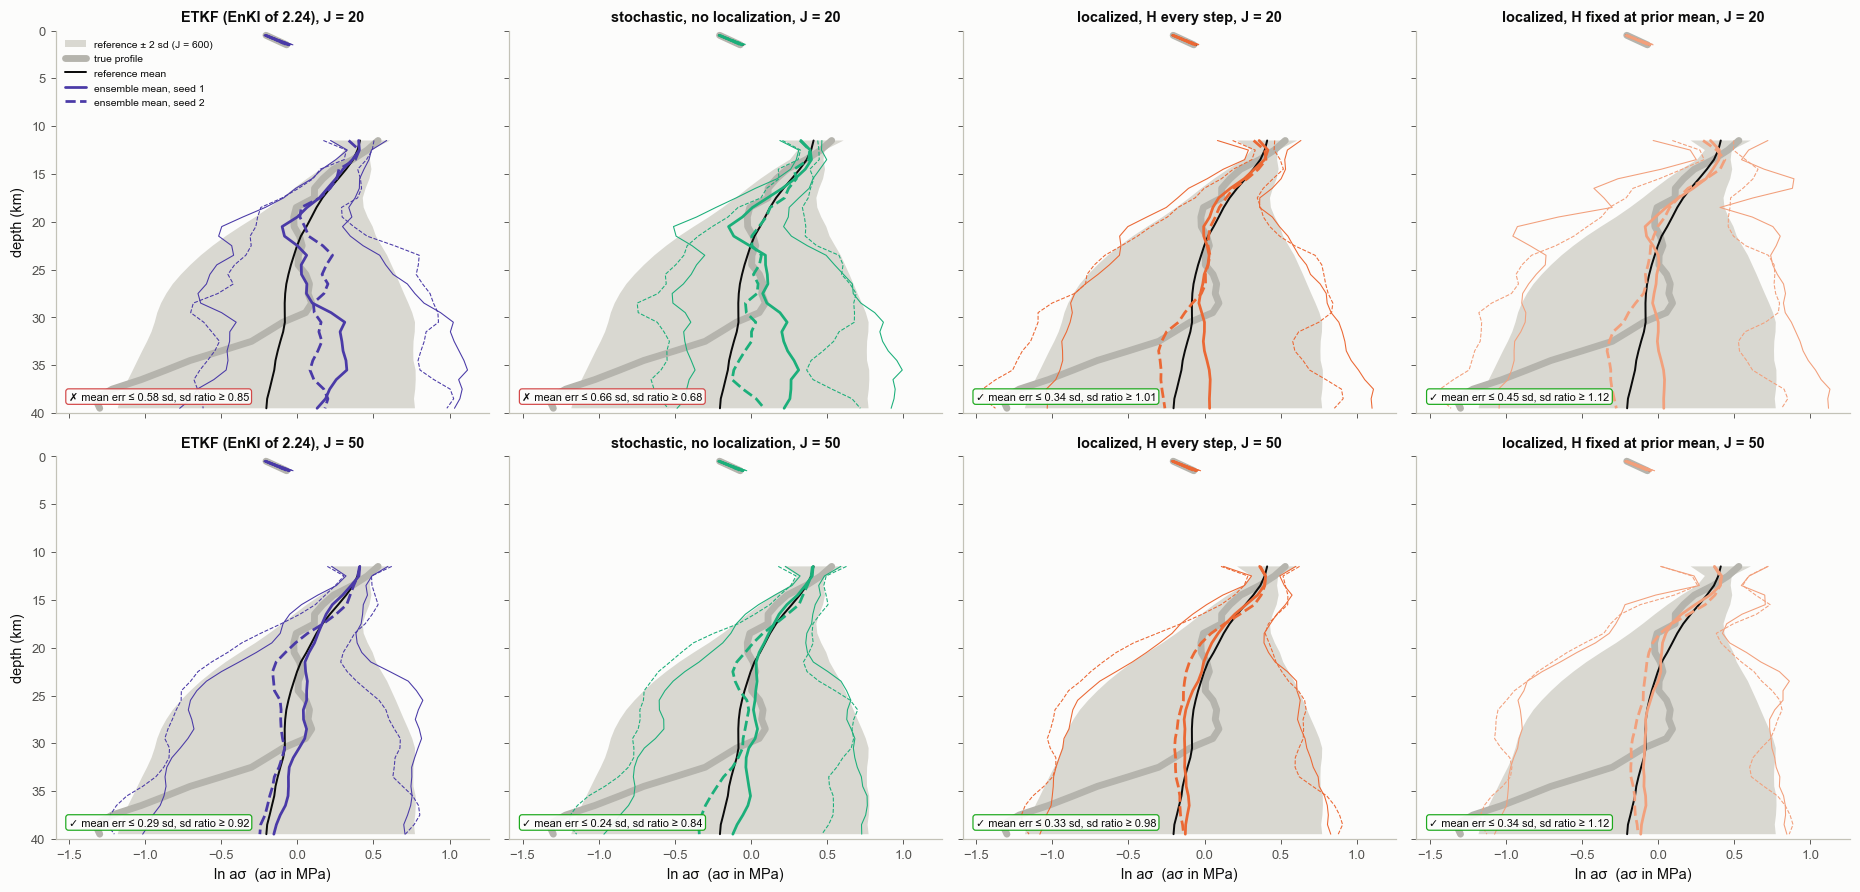

In [17]:
fig, axs = plt.subplots(2, 4, figsize=(17, 8.2), sharey=True, sharex=True)
for i, J in enumerate((20, 50)):
    for k, (name, _, col) in enumerate(F_METHODS):
        ax = axs[i, k]
        ax.fill_betweenx(zf_plot, gp(m_rf - 2 * sd_rf), gp(m_rf + 2 * sd_rf), color=EXACT_FILL, lw=0, label="reference ± 2 sd (J = 600)")
        ax.plot(gp(la_true), zf_plot, **TRUE_KW, label="true profile")
        ax.plot(gp(m_rf), zf_plot, color=S.INK, lw=1.3, label="reference mean")
        errs = []
        for seed, ls in ((3, "-"), (4, "--")):
            X = fruns[(J, name, seed)]["X"]
            m, s = X.mean(0), X.std(0, ddof=1)
            ax.plot(gp(m), zf_plot, color=col, lw=1.8, ls=ls, label=f"ensemble mean, seed {seed - 2}")
            ax.plot(gp(m - 2 * s), zf_plot, color=col, lw=0.7, ls=ls)
            ax.plot(gp(m + 2 * s), zf_plot, color=col, lw=0.7, ls=ls)
            errs.append(grade(X, m_rf, sd_rf))
        e = max(errs[0][0], errs[1][0]); sr = min(errs[0][1], errs[1][1])
        S.badge(ax, f"mean err ≤ {e:.2f} sd, sd ratio ≥ {sr:.2f}", ok=(e < 0.5 and sr > 0.8), loc="lower left", fs=7.2)
        ax.set_title(f"{name}, J = {J}", fontsize=9.5)
        ax.set_ylim(40, 0)
    axs[i, 0].set_ylabel("depth (km)")
for ax in axs[1]:
    ax.set_xlabel("ln aσ  (aσ in MPa)")
axs[0, 0].legend(fontsize=6.8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-26_fault_profiles")
plt.show()

**How to read it.** Grey band: the J = 600 reference; thick grey line: the true profile; coloured: two seeds of each
small ensemble (the gap between 2 and 11 km is the pinned patches). Read the table above for the numbers behind the
badges.
* **Same fit, different answers.** The final WRMS column is nearly identical for every run, so the data fit cannot
  tell a good small ensemble from a bad one (the same lesson as notebook 2.24, section 8).
* **J = 20.** Compare mean error and spread across the J = 20 rows. Both localized updates are closer to the
  reference than the ETKF, with a spread at or slightly above the reference's. The stochastic update without
  localization differs most between its two seeds: one lands close and the other does not (its seed-to-seed gap is
  the largest printed; two seeds are too few to say more). The "outside span" column
  again shows which runs are confined to the initial subspace; most of the deep profile (20-40 km), where the data are
  weakest, is where the unlocalized runs wander.
* **The Jacobian can be crude.** The run with $\mathbf H$ fixed at the prior mean, from one Jacobian (31 tangent
  runs) for the whole inversion, is nearly as good as the run that recomputes $\mathbf H$ at every step (somewhat
  wider, and further off for one seed). That is Tong & Morzfeld's remark in practice, for this problem: the printed
  Jacobian change between prior and reference mean is modest. For a forward model whose sensitivity changes sign or
  order of magnitude across the prior, it would not be.
* **J = 50.** Read the J = 50 rows: with more members the unlocalized runs improve, and localization's advantage
  disappears, as in the linear case.
* **Cost.** The table counts forward runs and tangent runs separately. Recomputing $\mathbf H$ at every step costs
  tangent runs comparable to the ensemble itself; the fixed Jacobian costs one set.

## 8. The two-seed test, measured

In a real inversion there is no exact or reference posterior to grade against. What you *can* compute is the gap
between two runs that differ only in the seed, in units of the runs' own spread (the **two-seed test**). Does that gap
predict the real error? Each point below is one pair of seeds from section 5 (linear; seeds paired 0-1, 2-3, ...) or
section 7 (nonlinear). The dotted line is the gap two sets of $J$ independent draws would show, $\sqrt{2/J}$.

saved figures/2-26_seed_test.png


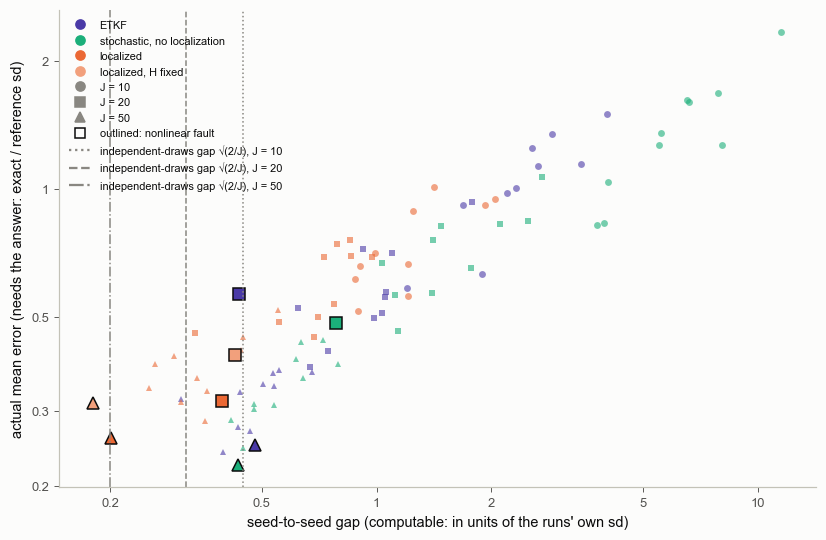

98 pairs; correlation between the computable gap and the actual error: 0.90
mean ratio (actual error) / (seed gap): 0.65


In [18]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
pts = []
for J, mk in zip(Js, ["o", "s", "^"]):
    for key, col in [("etkf", EN), ("sto", STO), (4, LOC)]:
        for p_ in range(0, NSEED, 2):
            Xa, Xb = sweep[(J, key, p_)], sweep[(J, key, p_ + 1)]
            gap = seed_gap(Xa, Xb)
            err = 0.5 * (grade(Xa, m_ex, sd_ex)[0] + grade(Xb, m_ex, sd_ex)[0])
            pts.append((gap, err))
            ax.plot(gap, err, mk, color=col, ms=4.5, alpha=0.6, mec="none")
for J, mk in zip((20, 50), ["s", "^"]):
    for name, _, col in F_METHODS:
        Xa, Xb = fruns[(J, name, 3)]["X"], fruns[(J, name, 4)]["X"]
        gap = seed_gap(Xa, Xb)
        err = 0.5 * (grade(Xa, m_rf, sd_rf)[0] + grade(Xb, m_rf, sd_rf)[0])
        pts.append((gap, err))
        ax.plot(gap, err, mk, color=col, ms=8, mec=S.INK, mew=1.0)
for J, ls in zip(Js, [":", "--", "-."]):
    ax.axvline(np.sqrt(2 / J), color=S.MUTED, lw=1, ls=ls)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10]); ax.set_xticklabels(["0.2", "0.5", "1", "2", "5", "10"])
ax.set_yticks([0.2, 0.3, 0.5, 1, 2]); ax.set_yticklabels(["0.2", "0.3", "0.5", "1", "2"])
ax.minorticks_off()
pts = np.array(pts)
ax.set_xlabel("seed-to-seed gap (computable: in units of the runs' own sd)")
ax.set_ylabel("actual mean error (needs the answer: exact / reference sd)")
ax.legend(handles=BP.legend_handles([("ETKF", EN, "dot"), ("stochastic, no localization", STO, "dot"),
                                     ("localized", LOC, "dot"), ("localized, H fixed", LOC2, "dot")]) +
          [plt.Line2D([], [], marker=m_, ls="", color=S.MUTED, label=f"J = {J}") for J, m_ in zip(Js, ["o", "s", "^"])] +
          [plt.Line2D([], [], marker="s", ls="", mfc="none", mec=S.INK, label="outlined: nonlinear fault")] +
          [plt.Line2D([], [], color=S.MUTED, ls=ls, label=f"independent-draws gap √(2/J), J = {J}") for J, ls in zip(Js, [":", "--", "-."])],
          fontsize=7.2, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-26_seed_test")
plt.show()
print(f"{len(pts)} pairs; correlation between the computable gap and the actual error: {np.corrcoef(pts.T)[0, 1]:.2f}")
print(f"mean ratio (actual error) / (seed gap): {np.mean(pts[:, 1] / pts[:, 0]):.2f}")

**How to read it.** Points to the right have two seeds that disagree more relative to their own spread; points higher
up are further from the right answer. The printed correlation says how well the computable gap tracks the error you
cannot compute. Two seeds that disagree by more than independent draws would ($\sqrt{2/J}$, dotted lines) are a
warning; two seeds that agree are necessary but not sufficient, because both can share the same bias (a Gaussian
update on a nonlinear problem, or a too-short c).

## 9. Summary

| update | needs | per iteration | fixes | does not fix |
|---|---|---|---|---|
| ETKF (the EnKI of 2.24) | forward runs | J runs | no perturbation noise (deterministic square root) | subspace property; narrow spread at small J |
| stochastic, no localization | forward runs | J runs | nothing by itself; it is the form a taper can enter | the same, plus perturbation noise |
| localized (linearised) | forward runs + a Jacobian, exact or approximate | J runs (+ tangents if H is recomputed) | spurious long-range correlations, rank, spread | a Gaussian update on a nonlinear problem; bias if c is too short |
| inflation | nothing | free | spread (crudely, tuned per problem) | the mean; missing directions |
| more members | forward runs | more runs | everything above, slowly ($1/\sqrt J$) | the Gaussian-update approximation |

Gjini et al. (2025, p. 26), on ensemble methods for climate-model calibration, put localization in the same place:
ensemble sizes that do not grow with the number of unknowns require "that the covariance estimates within the
ensemble iterations are improved via covariance localization or other covariance estimation or sampling error
correction methods".

**In practice.**
* A large inversion run with several hundred members for thousands of unknowns sits far to the few-members side of
  every figure here. The two-seed test (section 8) is the cheap first check; if seeds disagree by much more than
  $\sqrt{2/J}$ of their own spread, the error bars are not yet the posterior's.
* Localizing a square-root (ETKF) update means either switching to the stochastic form with a parameter-space taper
  (here, depth distance; on a 3-D fault, distance along the fault surface) and an approximate Jacobian, or a local
  analysis per patch group (LETKF). Section 7 suggests the Jacobian can be crude when the sensitivity does not change
  much across the prior; check that on the forward model at hand before relying on it.
* When the prior already encodes a correlation length (a Matérn ℓ, 2.12), the best c is where bias and noise
  balance for the J at hand (section 5), so scan c with two seeds rather than setting c = ℓ by default.

Next: [**2.27 · Entropy and information**](2-27_entropy_information.ipynb).

In [19]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 93 s
